# Reading the Reading Room
## M2 five-CNN baseline reconstruction and M3 hypothesis

Samarth Shekhar 230042, Meghavi Rao 230044, Rachit Kumar 230128, Harshal Nerpagar 230076.

Base paper: [Chouhan et al. 2020](https://doi.org/10.3390/app10020559). This is an independent reconstruction of the late-block boundaries in Figures4-8 using torchvision, with a bounded FIVE-epoch schedule. It differs from the stated50/100-epoch runs and AlexNet iteration schedule. The corrected run actually used an8 GiB Apple M2, one CPU model at a time. Earlier fully frozen probes are archived separately and are not the final ensemble. This executed notebook audits measured outputs and learned tails. Set MODE to `reproduce` to download data and train missing artifacts; the prepared Mac resumes existing complete models.

The proposed lung-focused crop is not implemented or measured here. M3 requires submitting a prediction first. No clinical, global novelty or state-of-the-art claim is made.

In [1]:
from pathlib import Path
import os, sys, json, platform
ROOT = Path.cwd()
if ROOT.name == 'output': ROOT = ROOT.parent
if not (ROOT/'baseline.py').exists() and (ROOT/'m2_m3').exists(): ROOT = ROOT/'m2_m3'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
MODE = 'inspect_saved'  # change to 'reproduce' only for a deliberate full run
print('Execution mode:', MODE)
print('Platform:', platform.platform())
print('Source code and real saved results directory:', ROOT)


Execution mode: inspect_saved
Platform: macOS-26.5-arm64-arm-64bit
Source code and real saved results directory: /Users/zebra/cvproj/m2_m3


## Assignment alignment

Stage 2 selects one base paper and checks reproducibility. Stage 3 reproduces its baseline. M2 submits a notebook with reproduced results. M3 submits one change, a numerical prediction and mechanism before implementing that change, plus an introduction in the report and presentation. M4 tests the change and ablations. We include sensitivity/recall, AUC and limitations as explicitly required.

# Reproducibility checklist

## P7 selected base paper

Chouhan et al., Applied Sciences 2020, 10(2), 559. https://doi.org/10.3390/app10020559

Full text inspected through the author repository PDF: https://eprints.qut.edu.au/199742/1/applsci_10_00559_1_.pdf.

| Item | Evidence and decision |
|---|---|
| Public code preferred | No paper-linked author repository verified in the paper or search. Our baseline.py is an independent reconstruction. PyTorch's official torchvision implementations supply the five backbones. |
| Public data | Kermany CXR, DOI 10.17632/rscbjbr9sj.2. Downloadable CC BY 4.0 mirror hf-vision/chest-xray-pneumonia. Original split counts 5216/16/624. Parquet source checksums checked before extraction. |
| Paper split | Table 1: 5232 training, 624 test, formed by combining original train and validation. Local baseline uses this partition and a fixed training budget. |
| Model identities | AlexNet, DenseNet121, InceptionV3, ResNet18, GoogLeNet, ImageNet-pretrained. Figures 4-8 specify frozen early layers and trainable late layers. Train ResNet layer4, DenseNet block4 layers15/16, Inception Mixed_7c and GoogLeNet inception5b plus classifiers. AlexNet replaces the classifier with 9216->512->2. Combine three-of-five votes. |
| Input | Paper starts with 224x224x3 resizing, then horizontal flips, random resized crops and varying intensity. Local initial resize is cached losslessly as PNG. |
| Objective and optimizer | Paper states Adam, cross entropy, initial LR 0.001, halved every three epochs. These are reconstructed locally. |
| Training duration departure | Paper says DenseNet/Inception100 epochs and GoogLeNet50. AlexNet starts with200 iterations at0.001 then an unspecified duration at0.00001; ResNet duration is unspecified. Local uses FIVE epochs for every model, with the same general learning-rate decay, and does not follow AlexNet's separate low-rate phase. This is shorter than the stated50/100-epoch runs but not a matching AlexNet iteration schedule. It is a bounded architecture reconstruction, not full-schedule replication. |
| Augmentation departure | Local has one clean and one fixed seeded augmented view per training image, sampled during head training, rather than a fresh image augmentation every epoch. The paper also mentions added noise without giving a distribution/scale; local reconstruction does not add a separate noise transform. Frozen features permit caching, but these are approximations and can change results. |
| Other unspecified settings | Paper does not provide seed, exact environment, crop/intensity settings, normalization, batch size or optimizer details. Local: seed 42, frozen-prefix feature batch4, training batch8, ImageNet mean/std, crop scale0.8-1.0, brightness/contrast0.15, Adam defaults. Cached frozen activations use float16 for disk space and convert to float32 during training. |
| BatchNorm and dropout | Frozen prefixes use evaluation mode. Trainable late blocks use training mode. DenseNet's post-block norm5 remains frozen/eval. AlexNet's replacement 512-unit classifier uses ReLU/dropout0.5, whose exact hidden activation/dropout is not specified in its diagram. GoogLeNet/Inception retain their standard dropout. |
| Metrics | Paper reports ensemble accuracy 96.39%, recall 99.62%, precision 93.28%, AUC 99.34%. Local reports these plus specificity, both class F1, macro F1 and balanced accuracy. AUC uses mean CNN probabilities; class labels use majority vote. Paper's AUC score construction is not specified. |
| Validation/test handling | Original train+val merged to match Table1. Five corrected epochs are fixed before testing; no test-based checkpoint/threshold selection. An earlier fully frozen diagnostic probe was tested, then discarded as the main baseline after inspecting the figures. Its outputs are retained separately, not mixed into the final ensemble. No held-out validation subset exists in the M2 paper-comparison protocol. |
| Hardware | 8 GiB Apple M2. One model at a time, bounded feature extraction, two CPU threads, memory/disk guards. Paper used GTX1070 and 48 GB host RAM. |
| Claim boundary | This is a method reconstruction, not a bit-for-bit reproduction of unavailable code. A near metric does not erase departures. Report the actual reproduction gap. |

## P9 assessment

Singh et al. 2024: https://pmc.ncbi.nlm.nih.gov/articles/PMC10827725/.

The verified pretrained model is DEIT_Base_Patch16_224, not a generic student ViT repository. Table 5 reports 30 epochs, 97.61% accuracy, sensitivity .949, specificity .981, F score .952, and AUC .966. Table 6 uses slightly different F-score rounding. It also includes confidence intervals.

The article states 80/10/10 splitting (4684/586/586), while class totals in its split table contradict its dataset distribution table. No fixed seed, split manifest or author training repository was verified. Therefore exact reproduction is not established. Full 30-epoch fine-tuning of the 85.8M-parameter model is not the selected local deadline task.

## Novelty check

CNN/ViT hybrid and ensemble approaches already exist. For example: https://pmc.ncbi.nlm.nih.gov/articles/PMC10248870/ (2023). The project contribution is a controlled, predicted and tested preprocessing change to our own reproduced baseline, as the assignment requests. We do not claim that lung cropping or hybrid models are globally new.


## Dataset preparation code

Source parquet SHA256 checksums are verified. Only one shard is downloaded at a time. We cache the paper's initial RGB 224x224 bilinear resize as lossless PNG to keep disk usage bounded. Source hashes and original filenames stay in the manifest. Redundant task-owned parquet caches are removed after extraction.

In [2]:
"""Download one verified mirror shard at a time, retain original encoded images."""
import hashlib, io, json, subprocess, time
from pathlib import Path
import pyarrow.parquet as pq
from PIL import Image

ROOT=Path.cwd()
DATA=ROOT/'data'; DATA.mkdir(exist_ok=True)
BASE='https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia/resolve/main/'
def prepare():
    (ROOT/'sources').mkdir(exist_ok=True)
    p=subprocess.run(['curl','-fLsS','--retry','2','--max-time','60','https://huggingface.co/api/datasets/hf-vision/chest-xray-pneumonia/tree/main/data'],capture_output=True,text=True,check=True)
    files=json.loads(p.stdout)
    (ROOT/'sources'/'dataset_files.json').write_text(json.dumps(files,indent=2))
    records=[]
    # The original test is retained for comparison, never used to train/tune.
    for info in files:
        remote=info['path']; split=Path(remote).name.split('-')[0]
        shard=DATA/Path(remote).name
        done=shard.with_suffix('.manifest.json')
        if done.exists(): records.extend(json.loads(done.read_text()));continue
        print('Downloading',remote,info['size']/1e6,'MB',flush=True)
        subprocess.run(['curl','-fLsS','--retry','3','--max-time','900','--limit-rate','8M',BASE+remote,'-o',str(shard)],check=True)
        digest=hashlib.sha256(shard.read_bytes()).hexdigest()
        if digest!=info['lfs']['oid']: raise RuntimeError('Shard checksum mismatch')
        out=[]
        pf=pq.ParquetFile(shard)
        for batch in pf.iter_batches(batch_size=16):
            for row in batch.to_pylist():
                raw=row['image']['bytes']; sha=hashlib.sha256(raw).hexdigest(); label=int(row['label'])
                target=DATA/'images'/split/str(label)/(sha+'.png');target.parent.mkdir(parents=True,exist_ok=True)
                # Cache paper's initial 224x224 RGB resize losslessly to save disk.
                with Image.open(io.BytesIO(raw)) as im:
                    w,h=im.size
                    if not target.exists():im.convert('RGB').resize((224,224),Image.Resampling.BILINEAR).save(target)
                out.append(dict(path=str(target.relative_to(ROOT)),split=split,label=label,sha256=sha,width=w,height=h,source_path=row['image'].get('path')))
        done.write_text(json.dumps(out,indent=2));records.extend(out)
        # Own downloaded cache only; original JPEG bytes and checksums retained.
        shard.unlink()
        print('Verified/extracted',len(out),'images; removed redundant parquet cache',flush=True)
    (DATA/'manifest.json').write_text(json.dumps(records,indent=2))
    print('Manifest records',len(records),'unique files',len({r['sha256'] for r in records}),flush=True)


In [3]:
manifest_file = ROOT/'data/manifest.json'
data_ready = manifest_file.exists() and all((ROOT/r['path']).exists() for r in json.loads(manifest_file.read_text()))
if MODE == 'reproduce' and not data_ready:
    prepare()
else:
    print('Saved-results inspection or existing verified image cache retained.')

Saved-results inspection or existing verified image cache retained.


## Actual dataset audit

The paper training partition merges original train and val: 5,232 training records. Test has 624 records. Checkpoint and decision thresholds are not selected on the test set. Exact hashes do not certify patient independence.

In [4]:
import json, collections, hashlib
from pathlib import Path
ROOT=Path.cwd()
def audit():
    rows=json.loads((ROOT/'data/manifest.json').read_text())
    counts={s:{str(c):sum(r['split']==s and r['label']==c for r in rows) for c in [0,1]} for s in ['train','validation','test']}
    train=[r for r in rows if r['split']!='test'];test=[r for r in rows if r['split']=='test']
    tr={r['sha256'] for r in train};te={r['sha256'] for r in test}
    out=dict(counts=counts,total_records=len(rows),unique_source_images=len({r['sha256'] for r in rows}),train_records=len(train),test_records=len(test),unique_train=len(tr),unique_test=len(te),exact_hash_overlap=len(tr&te),source='hf-vision/chest-xray-pneumonia',source_dataset='10.17632/rscbjbr9sj.2',manifest_sha256=hashlib.sha256((ROOT/'data/manifest.json').read_bytes()).hexdigest(),cache='RGB bilinear initial resize 224x224, lossless PNG',test_majority_accuracy=.625)
    assert out['exact_hash_overlap']==0
    (ROOT/'results').mkdir(exist_ok=True);(ROOT/'results/dataset_audit.json').write_text(json.dumps(out,indent=2))
    return out


In [5]:
a = audit()
print(json.dumps(a, indent=2))

{
  "counts": {
    "train": {
      "0": 1341,
      "1": 3875
    },
    "validation": {
      "0": 8,
      "1": 8
    },
    "test": {
      "0": 234,
      "1": 390
    }
  },
  "total_records": 5856,
  "unique_source_images": 5824,
  "train_records": 5232,
  "test_records": 624,
  "unique_train": 5206,
  "unique_test": 618,
  "exact_hash_overlap": 0,
  "source": "hf-vision/chest-xray-pneumonia",
  "source_dataset": "10.17632/rscbjbr9sj.2",
  "manifest_sha256": "e8e4215c9967e95b8ad1472454749d664f23fc6490e061e40a90482b0452d753",
  "cache": "RGB bilinear initial resize 224x224, lossless PNG",
  "test_majority_accuracy": 0.625
}


## Full baseline training code

Frozen early prefixes, trainable late blocks/classifiers from Figures4-8, Adam/cross entropy and majority voting. No lung-crop code is present. Five epochs, two fixed views and float16 prefix caches are declared resource approximations; training converts activations to float32. Feature batches are4, training batches8 and CPU threads2. Resource guards stop on low memory/disk. Training-view caches are removed after each completed model; test prefix activations are retained for verification.

In [6]:
"""P7 Figures 4-8 reconstruction; five-epoch budget is explicitly declared.
Cached frozen prefixes, trainable stated late blocks, CPU two threads only.
"""
import os
os.environ.setdefault('OMP_NUM_THREADS','2');os.environ.setdefault('OPENBLAS_NUM_THREADS','2');os.environ.setdefault('VECLIB_MAXIMUM_THREADS','2')
import gc,json,time,csv,argparse
from pathlib import Path
import numpy as np,psutil,torch
from torch import nn
from torchvision import models,transforms
from PIL import Image
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,roc_auc_score,confusion_matrix,balanced_accuracy_score
ROOT=Path.cwd()
torch.set_num_threads(2)
if torch.get_num_interop_threads()!=1:torch.set_num_interop_threads(1)
MODEL_NAMES=['resnet18','densenet121','googlenet','inception_v3','alexnet'];SEED=42;EPOCHS=5
def guard():
    if psutil.Process().memory_info().rss>2.6*1024**3 or psutil.virtual_memory().available<650*1024**2:raise RuntimeError('Memory resource guard')
    if psutil.disk_usage(str(ROOT)).free<700*1024**2:raise RuntimeError('Disk resource guard')
class Captured(Exception):pass
class Prefix(nn.Module):
    def __init__(self,model,target):
        super().__init__();self.model=model;self.value=None;self.handle=target.register_forward_pre_hook(self.capture)
    def capture(self,module,inputs):
        x=inputs[0];self.value=torch.cat(x,1) if isinstance(x,list) else x;raise Captured()
    def forward(self,x):
        try:self.model(x)
        except Captured:
            z=self.value;self.value=None;return z
        raise RuntimeError('Prefix target not reached')
class DenseTail(nn.Module):
    def __init__(self,m):
        super().__init__();b=m.features.denseblock4;self.layer15=b.denselayer15;self.layer16=b.denselayer16;self.norm=m.features.norm5;self.fc=nn.Linear(1024,2)
    def forward(self,x):
        x=torch.cat([x,self.layer15(x)],1);x=torch.cat([x,self.layer16(x)],1)
        return self.fc(nn.functional.adaptive_avg_pool2d(torch.relu(self.norm(x)),(1,1)).flatten(1))
def build_model(name):
    torch.manual_seed(SEED);m=getattr(models,name)(weights='DEFAULT')
    if hasattr(m,'aux_logits'):m.aux_logits=False
    for p in m.parameters():p.requires_grad=False
    if name=='resnet18':target=m.layer4;tail=nn.Sequential(target,nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Linear(512,2));boundary='layer4 + fc'
    elif name=='densenet121':target=m.features.denseblock4.denselayer15;tail=DenseTail(m);boundary='denseblock4.denselayer15 + denselayer16 + classifier'
    elif name=='googlenet':target=m.inception5b;tail=nn.Sequential(target,nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Dropout(.2),nn.Linear(1024,2));boundary='inception5b + fc'
    elif name=='inception_v3':target=m.Mixed_7c;tail=nn.Sequential(target,nn.AdaptiveAvgPool2d((1,1)),nn.Flatten(),nn.Dropout(.5),nn.Linear(2048,2));boundary='Mixed_7c + fc'
    else:
        m.classifier=nn.Identity();target=m.classifier;tail=nn.Sequential(nn.Linear(9216,512),nn.ReLU(),nn.Dropout(.5),nn.Linear(512,2));boundary='9216->512->2 replacement classifier'
    prefix=Prefix(m,target).eval()
    for p in tail.parameters():p.requires_grad=True
    if isinstance(tail,DenseTail):
        for p in tail.norm.parameters():p.requires_grad=False
    return prefix,tail,boundary
def load_records():
    rows=json.loads((ROOT/'data/manifest.json').read_text());tr=[r for r in rows if r['split']!='test'];te=[r for r in rows if r['split']=='test']
    assert len(tr)==5232 and len(te)==624 and not ({r['sha256'] for r in tr}&{r['sha256'] for r in te});return tr,te
def features(name,prefix,records,view):
    cache=ROOT/'cache_tail';cache.mkdir(exist_ok=True);f=cache/f'{name}_{view}.npy';marker=f.with_suffix('.progress.json')
    if f.exists() and not marker.exists():return np.load(f,mmap_mode='r')
    norm=transforms.Normalize([.485,.456,.406],[.229,.224,.225])
    t=transforms.Compose([transforms.Resize((224,224)),transforms.RandomHorizontalFlip(),transforms.RandomResizedCrop(224,scale=(.8,1)),transforms.ColorJitter(brightness=.15,contrast=.15),transforms.ToTensor(),norm]) if view=='aug' else transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),norm])
    start=json.loads(marker.read_text())['next'] if marker.exists() else 0;out=None
    if not marker.exists():marker.write_text(json.dumps({'next':0}))
    for i in range(start,len(records),4):
        guard();xs=[]
        for j,r in enumerate(records[i:i+4],i):
            torch.manual_seed(SEED+j+(100000 if view=='aug' else 0))
            with Image.open(ROOT/r['path']) as im:xs.append(t(im.convert('RGB')))
        with torch.inference_mode():z=prefix(torch.stack(xs)).numpy().astype(np.float16)
        if out is None:out=np.lib.format.open_memmap(f,mode='r+' if f.exists() else 'w+',dtype='float16',shape=(len(records),*z.shape[1:]))
        out[i:i+len(z)]=z;marker.write_text(json.dumps({'next':i+len(z)}))
        if i%512==0:print(name,view,i,'/',len(records),'RSS MB',round(psutil.Process().memory_info().rss/1e6),flush=True)
        time.sleep(.025)
    out.flush();del out;marker.unlink();return np.load(f,mmap_mode='r')
def evaluate(y,prob,pred=None):
    pred=(prob>=.5).astype(int) if pred is None else pred;tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(n=len(y),accuracy=float(accuracy_score(y,pred)),sensitivity=float(recall_score(y,pred)),specificity=float(tn/(tn+fp)),precision=float(precision_score(y,pred,zero_division=0)),pneumonia_f1=float(f1_score(y,pred)),normal_f1=float(f1_score(y,pred,pos_label=0)),macro_f1=float(f1_score(y,pred,average='macro')),balanced_accuracy=float(balanced_accuracy_score(y,pred)),auc=float(roc_auc_score(y,prob)),confusion_matrix=[[int(tn),int(fp)],[int(fn),int(tp)]])
def fit(name,tail,clean,aug,y):
    torch.manual_seed(SEED);rng=np.random.default_rng(SEED);opt=torch.optim.Adam([p for p in tail.parameters() if p.requires_grad],lr=.001);hist=[];steps=0
    for epoch in range(EPOCHS):
        tail.train()
        if isinstance(tail,DenseTail):tail.norm.eval()
        lr=.001*.5**(epoch//3)
        for g in opt.param_groups:g['lr']=lr
        losses=[];order=rng.permutation(len(y))
        for i in range(0,len(y),8):
            guard();ix=order[i:i+8];a=rng.random(len(ix))<.5;x=np.array(clean[ix],dtype=np.float32,copy=True);x[a]=aug[ix[a]].astype(np.float32)
            opt.zero_grad(set_to_none=True);loss=nn.functional.cross_entropy(tail(torch.from_numpy(x)),torch.from_numpy(y[ix]).long());loss.backward();opt.step();losses.append(float(loss.detach()));steps+=1;time.sleep(.008)
            if i%1024==0:print('Training',name,'epoch',epoch+1,'record',i,'/',len(y),flush=True)
        hist.append(dict(epoch=epoch+1,steps=steps,loss=float(np.mean(losses)),learning_rate=lr));print('EPOCH',name,hist[-1],flush=True)
    tail.eval();return tail,hist
def predict(tail,x):
    p=[]
    with torch.inference_mode():
        for i in range(0,len(x),8):p.extend(tail(torch.from_numpy(np.array(x[i:i+8],dtype=np.float32,copy=True))).softmax(-1)[:,1].numpy())
    return np.array(p)
def main(names=MODEL_NAMES):
    train,test=load_records();y=np.array([r['label'] for r in train]);yt=np.array([r['label'] for r in test]);out=ROOT/'results';out.mkdir(exist_ok=True)
    for name in names:
        if all(f.exists() for f in [out/f'{name}.json',out/f'{name}_head.pt',out/f'{name}_probabilities.npy',ROOT/'cache_tail'/f'{name}_test.npy']):continue
        started=time.time();prefix,tail,boundary=build_model(name);clean=features(name,prefix,train,'train');aug=features(name,prefix,train,'aug');xt=features(name,prefix,test,'test')
        prefix.handle.remove();del prefix;gc.collect();tail,h=fit(name,tail,clean,aug,y);prob=predict(tail,xt);met=evaluate(yt,prob)
        torch.save(tail.state_dict(),out/f'{name}_head.pt');np.save(out/f'{name}_probabilities.npy',prob)
        (out/f'{name}.json').write_text(json.dumps(dict(model=name,metrics=met,history=h,seed=SEED,trainable_boundary=boundary,epochs=EPOCHS,seconds=time.time()-started,protocol='Figures 4-8 late-block fine-tuning; five-epoch bounded reconstruction'),indent=2));print('RESULT',name,json.dumps(met),flush=True)
        del clean,aug,xt,tail;gc.collect()
        for view in ['train','aug']:(ROOT/'cache_tail'/f'{name}_{view}.npy').unlink()
    if all((out/f'{n}.json').exists() for n in MODEL_NAMES):
        pp=np.stack([np.load(out/f'{n}_probabilities.npy') for n in MODEL_NAMES]);votes=(pp>=.5).sum(0);pred=(votes>=3).astype(int);score=pp.mean(0)
        result=dict(majority_vote=evaluate(yt,score,pred),majority_class=evaluate(yt,np.ones(len(yt))),models=MODEL_NAMES,train_n=len(train),test_n=len(test),seed=SEED,device='cpu',threads=2,feature_batch=4,training_batch=8,epochs=EPOCHS,protocol='Late-block fine-tuning; five epochs; fixed cached augmentation; float16 frozen activations',score_definition='Labels: majority vote. AUC: mean probability.')
        rng=np.random.default_rng(SEED);boot={k:[] for k in ['accuracy','sensitivity','specificity','macro_f1','auc']}
        for _ in range(1000):
            ix=rng.integers(0,len(yt),len(yt));e=evaluate(yt[ix],score[ix],pred[ix])
            for k in boot:boot[k].append(e[k])
        result['bootstrap_95_ci']={k:np.quantile(v,[.025,.975]).tolist() for k,v in boot.items()};(out/'summary.json').write_text(json.dumps(result,indent=2))
        with (out/'test_predictions.csv').open('w') as f:
            w=csv.writer(f);w.writerow(['path','sha256','true_label','predicted_label','mean_pneumonia_probability','pneumonia_votes',*MODEL_NAMES])
            for i,r in enumerate(test):w.writerow([r['path'],r['sha256'],yt[i],pred[i],score[i],votes[i],*pp[:,i]])
        print('ENSEMBLE',json.dumps(result),flush=True)


In [7]:
if MODE == 'reproduce':
    main()
else:
    print('Five models were trained in the bounded local run. Inspecting saved measured outputs.')
    assert all((ROOT/'results'/f'{n}.json').exists() for n in MODEL_NAMES)

Five models were trained in the bounded local run. Inspecting saved measured outputs.


## Independent verification of learned classifiers

This recomputes headline metrics, reloads all five learned late blocks/classifiers and predicts from cached frozen test-prefix activations. Predictions must match their saved probabilities. The receipt also reports a618-unique-image sensitivity analysis and file hashes.

In [8]:
"""Independently recompute every headline from per-image saved probabilities."""
import json,hashlib
from pathlib import Path
import numpy as np
from sklearn.metrics import accuracy_score,recall_score,precision_score,f1_score,roc_auc_score,confusion_matrix,balanced_accuracy_score
ROOT=Path.cwd()
def verify(require_heads=True):
    manifest=json.loads((ROOT/'data/manifest.json').read_text())
    test=[r for r in manifest if r['split']=='test'];y=np.array([r['label'] for r in test])
    summary=json.loads((ROOT/'results/summary.json').read_text());names=summary['models']
    p=np.stack([np.load(ROOT/'results'/f'{n}_probabilities.npy') for n in names])
    assert p.shape==(5,624) and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    pr=(p>=.5).sum(0)>=3;s=p.mean(0)
    tn,fp,fn,tp=confusion_matrix(y,pr).ravel()
    independently=dict(accuracy=float(accuracy_score(y,pr)),sensitivity=float(recall_score(y,pr)),specificity=float(tn/(tn+fp)),precision=float(precision_score(y,pr)),pneumonia_f1=float(f1_score(y,pr)),macro_f1=float(f1_score(y,pr,average='macro')),normal_f1=float(f1_score(y,pr,pos_label=0)),auc=float(roc_auc_score(y,s)),balanced_accuracy=float(balanced_accuracy_score(y,pr)))
    for k,v in independently.items():assert abs(v-summary['majority_vote'][k])<1e-12,(k,v)
    # Predictions from the learned saved heads must match the logged output.
    import torch
    heads_present=all((ROOT/'cache_tail'/f'{n}_test.npy').exists() and (ROOT/'results'/f'{n}_head.pt').exists() for n in names)
    if require_heads and not heads_present:raise RuntimeError('Saved heads or test features missing: run reproduction first.')
    for n in (names if heads_present else []):
        x=np.load(ROOT/'cache_tail'/f'{n}_test.npy',mmap_mode='r')
        state=torch.load(ROOT/'results'/f'{n}_head.pt',map_location='cpu',weights_only=True)
        constructor=globals().get('build_model')
        if constructor is None:
            from baseline import build_model as constructor
        prefix,h,_=constructor(n)
        prefix.handle.remove()
        del prefix
        h.load_state_dict(state);h.eval();res=[]
        with torch.inference_mode():
            for i in range(0,len(x),8):res.extend(h(torch.from_numpy(np.array(x[i:i+8],dtype=np.float32,copy=True))).softmax(-1)[:,1].numpy())
        assert np.allclose(res,np.load(ROOT/'results'/f'{n}_probabilities.npy'),atol=1e-7)
    unique=[];seen=set()
    for i,r in enumerate(test):
        if r['sha256'] not in seen:unique.append(i);seen.add(r['sha256'])
    u=np.array(unique)
    unique_metrics=dict(n=len(u),accuracy=float(accuracy_score(y[u],pr[u])),macro_f1=float(f1_score(y[u],pr[u],average='macro')),auc=float(roc_auc_score(y[u],s[u])))
    files=[ROOT/'baseline.py',ROOT/'data/manifest.json',ROOT/'results/test_predictions.csv',ROOT/'HYPOTHESIS_BEFORE_IMPLEMENTATION.md']
    receipt=dict(status='passed',independently_recomputed=independently,confusion_matrix=[[int(tn),int(fp)],[int(fn),int(tp)]],saved_heads_predictions_verified=heads_present,unique_test_sensitivity_analysis=unique_metrics,sha256={str(f.relative_to(ROOT)):hashlib.sha256(f.read_bytes()).hexdigest() for f in files})
    (ROOT/'results/verification.json').write_text(json.dumps(receipt,indent=2))
    print(json.dumps(receipt,indent=2));return receipt


In [9]:
import torch
torch.set_num_threads(2)
receipt = verify(require_heads=(MODE == 'reproduce'))
if not receipt['saved_heads_predictions_verified']:
    print('Portable package: per-image scores verified. Learned-head verification requires local caches or reproduction mode.')

{
  "status": "passed",
  "independently_recomputed": {
    "accuracy": 0.8717948717948718,
    "sensitivity": 0.9974358974358974,
    "specificity": 0.6623931623931624,
    "precision": 0.8311965811965812,
    "pneumonia_f1": 0.9067599067599068,
    "macro_f1": 0.8508158508158508,
    "normal_f1": 0.7948717948717948,
    "auc": 0.9815362699978085,
    "balanced_accuracy": 0.8299145299145299
  },
  "confusion_matrix": [
    [
      155,
      79
    ],
    [
      1,
      389
    ]
  ],
  "saved_heads_predictions_verified": true,
  "unique_test_sensitivity_analysis": {
    "n": 618,
    "accuracy": 0.872168284789644,
    "macro_f1": 0.8509866162040075,
    "auc": 0.9813975860487488
  },
  "sha256": {
    "baseline.py": "1a4003bdc4362e21161580f9d5afb7bbaf91aac1418b4c145ae4ab2c432f9884",
    "data/manifest.json": "e8e4215c9967e95b8ad1472454749d664f23fc6490e061e40a90482b0452d753",
    "results/test_predictions.csv": "cea1df931b237e490f85ecc00d985dd18862ed982c38b536cdea8cd23f49ecdf",
    

## Measured results

These values come from the completed run artifacts, not from paper values or predictions. Ensemble labels use at least three pneumonia votes. ROC AUC uses mean pneumonia probability as the continuous ensemble score.

In [10]:
import pandas as pd
summary = json.loads((ROOT/'results/summary.json').read_text())
metrics = ['accuracy','sensitivity','specificity','precision','pneumonia_f1','normal_f1','macro_f1','auc']
rows=[]
for name in MODEL_NAMES:
    r=json.loads((ROOT/'results'/f'{name}.json').read_text())
    rows.append({'model':name,**{k:r['metrics'][k] for k in metrics}})
rows.append({'model':'five_CNN_majority_vote',**{k:summary['majority_vote'][k] for k in metrics}})
display(pd.DataFrame(rows).set_index('model').round(4))
print('Paper target: accuracy .9639, sensitivity .9962, precision .9328, AUC .9934')
print('Our accuracy minus paper, percentage points:',100*(summary['majority_vote']['accuracy']-.9639))
print('Image-level bootstrap intervals, single training seed:',json.dumps(summary['bootstrap_95_ci'],indent=2))


,accuracy,sensitivity,specificity,precision,pneumonia_f1,normal_f1,macro_f1,auc
model,,,,,,,,
resnet18,0.8718,0.9974,0.6624,0.8312,0.9068,0.7949,0.8508,0.9800
densenet121,0.8478,0.9974,0.5983,0.8054,0.8912,0.7467,0.8189,0.9746
googlenet,0.8686,0.9923,0.6624,0.8305,0.9042,0.7908,0.8475,0.9748
inception_v3,0.8510,0.9897,0.6197,0.8126,0.8925,0.7572,0.8248,0.9714
alexnet,0.8734,0.9923,0.6752,0.8359,0.9074,0.8000,0.8537,0.9754
five_CNN_majority_vote,0.8718,0.9974,0.6624,0.8312,0.9068,0.7949,0.8508,0.9815


Paper target: accuracy .9639, sensitivity .9962, precision .9328, AUC .9934
Our accuracy minus paper, percentage points: -9.210512820512818
Image-level bootstrap intervals, single training seed: {
  "accuracy": [
    0.8461137820512821,
    0.8974759615384615
  ],
  "sensitivity": [
    0.9921465968586387,
    1.0
  ],
  "specificity": [
    0.5981497336377474,
    0.723852685586626
  ],
  "macro_f1": [
    0.8187413279743453,
    0.8813760548833668
  ],
  "auc": [
    0.9711362984140939,
    0.9896473118169873
  ]
}


## Confusion matrix and ROC curve

Labels are normal 0 and pneumonia 1. Specificity is normal-class recall. AUC measures score ranking across thresholds. Image-level bootstrap intervals do not include training-seed variability and may be optimistic with repeated or related images.

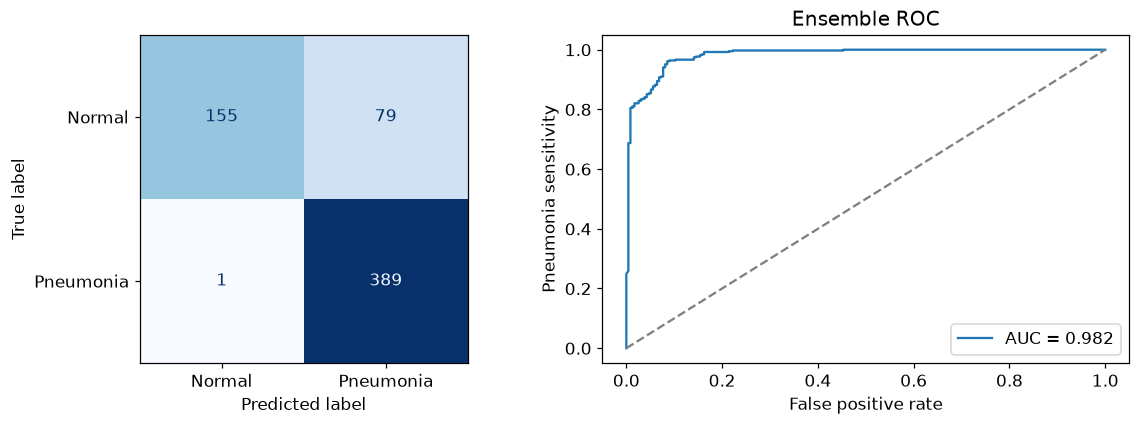

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
import numpy as np
plt.rcParams.update({'figure.dpi':110,'font.size':11})
manifest=json.loads((ROOT/'data/manifest.json').read_text())
test=[r for r in manifest if r['split']=='test']
y=np.array([r['label'] for r in test])
probs=np.stack([np.load(ROOT/'results'/f'{n}_probabilities.npy') for n in MODEL_NAMES])
pred=(probs>=.5).sum(0)>=3
fig,axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay(np.asarray(summary['majority_vote']['confusion_matrix']),display_labels=['Normal','Pneumonia']).plot(ax=axes[0],colorbar=False,cmap='Blues')
fpr,tpr,_=roc_curve(y,probs.mean(0))
axes[1].plot(fpr,tpr,label=f"AUC = {summary['majority_vote']['auc']:.3f}")
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].set(xlabel='False positive rate',ylabel='Pneumonia sensitivity',title='Ensemble ROC');axes[1].legend()
fig.tight_layout();fig.savefig(ROOT/'results/confusion_and_roc.png',bbox_inches='tight');plt.show()


## Actual training histories

Fixed schedules were decided before final testing. The following curves use saved epoch losses. There was no test-score-driven checkpoint selection.

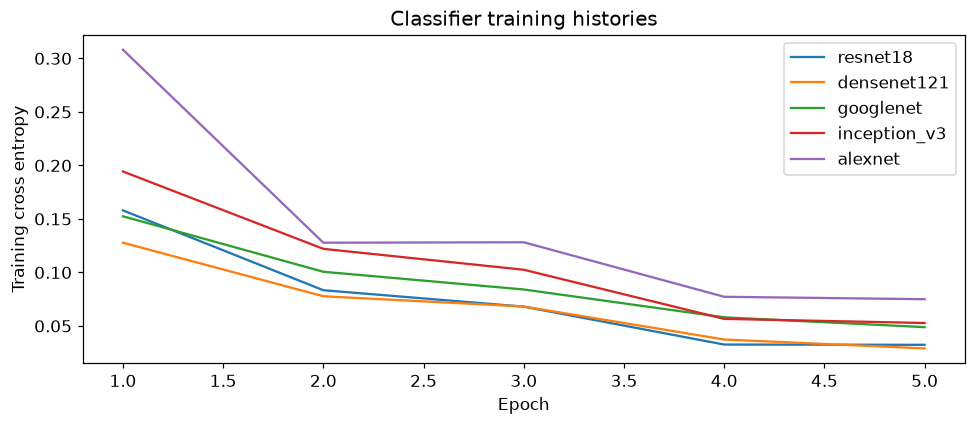

In [12]:
fig,ax=plt.subplots(figsize=(9,4))
for n in MODEL_NAMES:
    h=json.loads((ROOT/'results'/f'{n}.json').read_text())['history']
    ax.plot([r['epoch'] for r in h],[r['loss'] for r in h],label=n)
ax.set(xlabel='Epoch',ylabel='Training cross entropy',title='Classifier training histories');ax.legend();fig.tight_layout();plt.show()


## Why accuracy alone is insufficient

An always-pneumonia predictor does not need any image. We compute its test score below. High pneumonia F1 can coexist with zero normal recall. A small dataset or class imbalance does not automatically imply low F1 or overfitting.

In [13]:
constant = evaluate(y, np.ones(len(y)))
print(json.dumps(constant,indent=2))

{
  "n": 624,
  "accuracy": 0.625,
  "sensitivity": 1.0,
  "specificity": 0.0,
  "precision": 0.625,
  "pneumonia_f1": 0.7692307692307693,
  "normal_f1": 0.0,
  "macro_f1": 0.38461538461538464,
  "balanced_accuracy": 0.5,
  "auc": 0.5,
  "confusion_matrix": [
    [
      0,
      234
    ],
    [
      0,
      390
    ]
  ]
}


## Actual error examples

The examples below are misclassifications by our measured ensemble. They are qualitative inspection, not clinical diagnoses. Wrong predictions alone do not identify their cause.

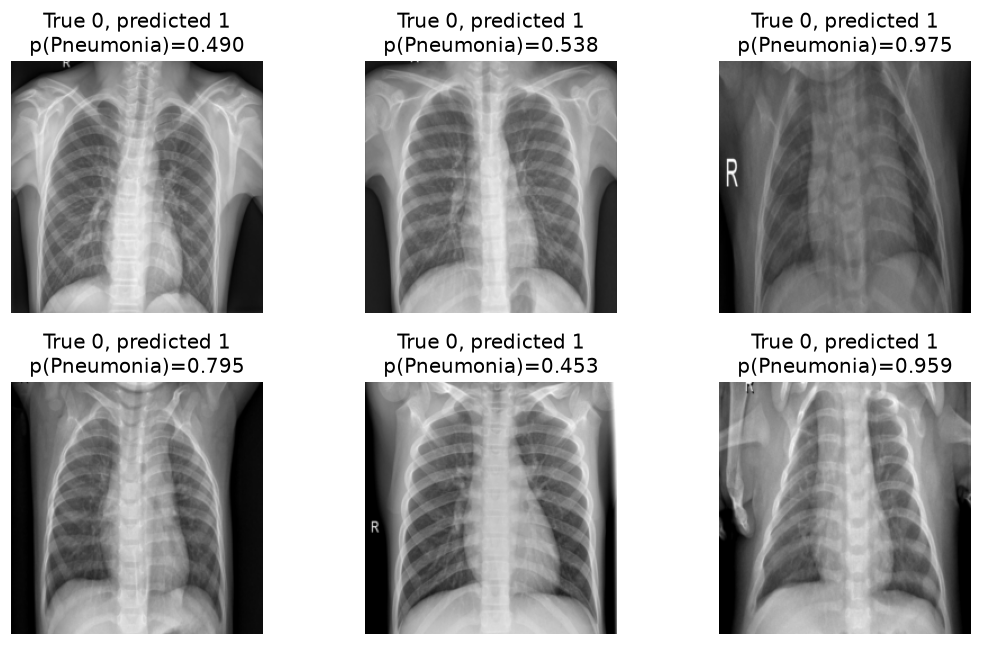

In [14]:
errors=np.flatnonzero(pred!=y)[:6]
from IPython.display import Image as DisplayImage
if not all((ROOT/test[i]['path']).exists() for i in errors):
    display(DisplayImage(filename=str(ROOT/'results/error_examples.png')))
else:
    fig,axes=plt.subplots(2,3,figsize=(10,6))
    for ax,i in zip(axes.flat,errors):
        ax.imshow(Image.open(ROOT/test[i]['path']),cmap='gray')
        ax.set_title(f"True {int(y[i])}, predicted {int(pred[i])}" + chr(10) + f"p(Pneumonia)={probs[:,i].mean():.3f}")
        ax.axis('off')
    for ax in list(axes.flat)[len(errors):]:ax.axis('off')
    fig.tight_layout();fig.savefig(ROOT/'results/error_examples.png',bbox_inches='tight');plt.show()


# M3 hypothesis and prediction

Recorded 5 October 2026. Status: proposed experiment, not implemented or measured.

## Selected baseline

P7: Chouhan et al., A Novel Transfer Learning Based Approach for Pneumonia Detection in Chest X-ray Images, Applied Sciences 10(2), 559, 2020. DOI: https://doi.org/10.3390/app10020559.

Five ImageNet-pretrained CNNs (AlexNet, DenseNet121, InceptionV3, ResNet18 and GoogLeNet) use frozen early feature layers and trainable late blocks/classifiers as specified by the paper's Figures4-8. Three or more pneumonia votes give the final label. Our local five-epoch schedule is a declared resource limit. This replaces the tentative Kermany/InceptionV3 baseline presented in M1 while retaining the change to image region.

## One change

Replace the full image with a lung-focused crop derived from a pretrained chest X-ray lung segmentation model. Use the union of both lung masks, expand its bounding box by a fixed 10% margin, then resize the crop to 224 by 224. Keep the same five classifiers, training schedule, augmentation, split, seed and majority-vote rule in the paired control and crop experiments.

For M4, obtain original-resolution pixels from the verified source shards again and crop BEFORE the initial 224-pixel resize. The current Mac cache contains only the M2 initial resize. Cropping that small cache and enlarging it would not recover lung detail. Process original images one shard at a time rather than storing the entire full-resolution collection. The paired full-image control will use those same source pixels and the same final resize.

Cropping is one input-preprocessing variable. It does not introduce a transformer, a new loss or a different voting rule. The segmentation model must be fixed and trained on separate data. Failed masks fall back to the full image, with the failure count reported. A crop is a bounding rectangle and can contain non-lung pixels. We do not claim that it removes all shortcuts.

The concrete candidate is TorchXRayVision's pretrained ChestX-Det PSPNet, whose official code exposes Left Lung and Right Lung channels: https://github.com/mlmed/torchxrayvision. Its documentation, source and segmentation demo have been inspected; its weights and crop experiment have not been run here. It outputs 14 anatomy channels at 512 pixels and comes from ChestX-Det, not Kermany. M4 will use its documented preprocessing, apply sigmoid to the output logits as in the official demo, and threshold the left/right lung probabilities at 0.5. Pediatric mask quality remains an explicit limitation.

## Hypothesis and mechanism

Lung-focused cropping may improve the balance between normal-class and pneumonia-class recognition by devoting more of the fixed input resolution to lung tissue and reducing peripheral image variation. It may also remove useful anatomy or fail on pediatric images, so improvement is uncertain.

## Numerical prediction before the experiment

Relative to an identically run full-image control, we predict **macro F1 increases by 0.01 to 0.03**, **normal-class recall (specificity) increases by 2 to 5 percentage points**, and **ROC AUC changes by 0.00 to +0.02**. We predict pneumonia recall changes within **minus 2 to plus 2 percentage points**, and accuracy within **minus 1 to plus 2 percentage points**. These are reasoned predictions, not results, confidence intervals or a claim of state of the art.

This updates M1's prediction of less than one percentage point accuracy movement: after changing the base paper, we make macro F1 and specificity the primary expected benefit. We retain the possibility of little or no accuracy improvement. No crop experiment has been run for M2/M3.

## M4 evaluation design

1. Construct one fixed training/validation split from original non-test data, grouping recoverable patient identifiers and removing exact duplicate overlap. Document any normal-image identifier ambiguity. Keep the original 624-image test set sealed for paired final evaluation. If duplicated test records are retained for paper comparability, also report a unique-image sensitivity analysis. Do not tune on test scores.
2. Re-run the full-image control under that split. The M2 paper-comparison score is not interchangeable with this new protocol's control score.
3. Run the lung-crop version with exactly the same settings. Select checkpoints by validation macro F1; break ties by higher validation AUC, then earlier epoch. Keep the component threshold0.5 and three-of-five vote fixed. Use no test scores for selection, then evaluate the paired final conditions on test.
4. Repeat paired runs for seeds 42, 43 and 44 if resources allow. Report the seed results and paired bootstrap intervals for metric differences. Do not infer significance from overlap of separate intervals.
5. Report accuracy, pneumonia sensitivity, specificity, precision, both class F1 scores, macro F1, AUC and confusion matrices. Include five to ten errors and segmentation failures.
6. Optional diagnostic ablation: apply the fixed crop at test time only to the full-image baseline. This is a distribution-shift test, not the main treatment. A peripheral-only stress test cannot by itself prove shortcut learning.

Grad-CAM examples can support qualitative discussion for individual CNNs. Heatmap overlap with a lung mask measures anatomical concentration, not correct lesion localization, clinical correctness or causal reasoning. There are no lesion annotations here.

## What would refute the prediction

No macro-F1 gain, substantially worse pneumonia recall, or a crop effect indistinguishable from zero across paired seeds would fail to support the hypothesis. We will report the measured outcome even if cropping hurts. The assignment explicitly allows a wrong prediction when reasoning and analysis are sound.

## Scope

This is a student research-reproduction project on a single-center pediatric benchmark. We make no clinical deployment claim and no novelty or state-of-the-art claim. M3 ends with this proposal and the report introduction. Implementation and ablations belong to M4 after submitting this hypothesis.


## Limitations and next milestone

One pediatric hospital and one baseline seed limit generalization. Repeated records remain in the paper-comparison protocol. There is no independent validation subset after merging the original train/val folders. Our reconstruction makes declared assumptions for missing author settings and uses finite cached augmentation. No model was tuned using final test results. The paper-comparison score does not prove exact code reproduction.

M4 will create a fixed group-aware validation protocol and rerun the full-image control under it before comparing the one crop change. The M2 score must not be compared directly to a crop result trained on a different split. Paired bootstrap intervals are planned for metric differences. Heatmaps can illustrate individual CNN activation, but cannot prove lesion localization or clinical correctness. The hypothesis experiment has not been run.

## Sources

- https://doi.org/10.3390/app10020559
- https://eprints.qut.edu.au/199742/1/applsci_10_00559_1_.pdf
- https://huggingface.co/datasets/hf-vision/chest-xray-pneumonia
- https://doi.org/10.17632/rscbjbr9sj.2
- https://github.com/pytorch/vision
- https://pmc.ncbi.nlm.nih.gov/articles/PMC10827725/
- https://pmc.ncbi.nlm.nih.gov/articles/PMC10248870/
